# Lab 8: Decisions

A model gives you a probability. In this lab you turn a probability into a decision.

1. St. Petersburg: compare risky choices with utility.
2. Kelly: why the best stake is not the one with the highest average payoff.
3. Benter: decide whether a bet is worth taking, and how much to stake.
4. Benter on 40 years of Hong Kong races: test the recipe on real data.
5. Allais: a choice that breaks expected utility.
6. Winner's curse and lemons: when a price misleads the buyer.
7. The value of a test: what information is worth in dollars.
8. The marble game: choosing when the other player also chooses.

Graded exercises 8.1 to 8.5 sit inside the sections, after the material they practise. The exit problem is on paper. Exercise 8.6 is done at home.

Rules for the notebook:

- Before a cell, read its **Predict** line and guess. Then run it.
- **Your turn** cells run as given. Change the line marked `# change this`.
- **Check yourself** answers are hidden in a fold. Try first.
- Sections 3 and 4 use real payouts. Section 3 types in one race by hand. Section 4 downloads one file, `hk_features.csv.gz` (18 MB), the first time you run it. All other data are simulated, made up, or typed in by hand. Each cell says which.


## Route for this lab

**By the end you should be able to:**

1. Say what a certainty equivalent is (St. Petersburg, utility).
2. Turn a probability and the payout into a stake, and say why a good bet can still lose money over time (Kelly, Benter).
3. Say when a test is worth its cost (value of information).
4. Explain why the winner of an auction, or the buyer in a market with hidden quality, can lose, and find a mixed-strategy equilibrium.

**In class (about 175 minutes):** Section 1 St. Petersburg and utility, 2 Kelly, 3 Benter, 4 Benter on 40 years of Hong Kong races, 5 Allais, 6 winner's curse and lemons, 7 value of a test, 8 Nash and the marble game. Exercises 8.1 to 8.5 sit inside the sections, after the material they practise. The exit problem is on paper.

**Required:** all sections, the Computing corners, and the graded exercises 8.1 to 8.6 (8.6 is the At home exercise).

**Due:** before class on 4 November. Submit this notebook on Canvas, with every code cell executed and the output left in. Credit is on-time submission.

Run All stops at the first empty exercise check; that is expected. Fill the exercises, then Restart and Run All before you submit. In each exercise, fill in the code cell, then run the check cell below it: `ok` means the number is right.


### Online labs for this notebook

- [Benter Betting Lab](https://vsokolov.org/labs/benter-lab.html): Sections 3 and 4, from the payout board to a stake, and the full model of Part II.
- [Decision Tree Lab](https://vsokolov.org/labs/decision-tree-lab.html): Section 7, the value of a test.
- [Base-Rate Lab](https://vsokolov.org/labs/base-rate-lab.html): Section 7, sensitivity, specificity and prevalence.
- [Calibration Lab](https://vsokolov.org/labs/calibration-lab.html): Sections 2 and 4, whether a model's numbers are real probabilities.


In [12]:
from hashlib import sha256

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def check(name, value, expected, ndigits=6):
    if value is None:
        raise AssertionError(f"{name} is still None: fill in the exercise cell above and run it")
    try:
        x = float(value)
    except (TypeError, ValueError):
        raise AssertionError(f"{name} should be one number, but it is {type(value).__name__}")
    if not np.isfinite(x):
        raise AssertionError(f"{name} is not a finite number ({x})")
    s = f"{round(x, ndigits):.{ndigits}f}"
    got = sha256(f"aii600-lab8|{name}|{s}".encode()).hexdigest()[:16]
    assert got == expected, f"{name} = {x:.6g} is not right: check the formula and the inputs"
    print("ok ", name)


## 1. St. Petersburg, utility, and risk attitudes

A game from the 1700s shows that the average payout is a poor guide to what a risky game is worth.

**History.** Nicolaus Bernoulli posed the game in 1713, in a letter to the French mathematician Pierre Rémond de Montmort. Its average payout is infinite, yet nobody would pay much to play. Nobody could explain why. In 1728 the Swiss mathematician Gabriel Cramer suggested that money is worth less to a person who already has more of it. In 1738 Daniel Bernoulli, Nicolaus's cousin, worked this idea out in a paper for the Imperial Academy of Sciences in St. Petersburg. That paper gave the game its name. Bernoulli proposed that the value of an extra dollar is inversely proportional to the wealth you already have. That rule gives log utility, $u(x) = \log x$. He then valued a gamble by its average utility instead of its average payout. This is the idea of expected utility. Two centuries later, in 1944, John von Neumann and Oskar Morgenstern gave rules for rational choice under which a person acts as if maximizing expected utility. Section 5 (Allais) shows a choice that breaks those rules.

**The game.** I toss a fair coin until the first head. If the first head is on toss $T$, I pay you $X = 2^T$ dollars, so $X$ is the payout in dollars. Toss 1 pays \$2, toss 2 pays \$4, toss 3 pays \$8. The chance that the first head is on toss $T$ is $2^{-T}$. The average payout is

$$
\mathbb{E}(X) = \sum_{T=1}^{\infty} 2^T \cdot 2^{-T} = 1 + 1 + 1 + \ldots = \infty.
$$

So a player who maximizes the average should pay any price to enter. Nobody does.

**Predict:** how much would you pay to play once? Write your number down. We collect the answers in the room.

The next cell plays the game on the computer (simulated). It plays $n$ rounds and takes the sample mean of the payouts, for $n$ from 100 to 100,000. It does this 200 times with different seeds, and prints the first run, the median of the 200 sample means, and the base-2 log of $n$.


In [13]:
rng = np.random.default_rng(3)
ns = [10**2, 10**3, 10**4, 10**5]
means = np.empty((200, len(ns)))
for r in range(200):
    T = rng.geometric(0.5, size=ns[-1])          # toss on which the first head appears
    payout = 2.0 ** T                            # dollars
    means[r] = [payout[:n].mean() for n in ns]
pd.DataFrame({'n': ns, 'first run': means[0].round(1),
              'median of 200 runs': np.median(means, axis=0).round(1),
              'log2(n)': np.log2(ns).round(1)}).set_index('n')


,first run,median of 200 runs,log2(n)
n,,,
100,6.1,8.9,6.6
1000,19.5,11.9,10.0
10000,19.1,15.9,13.3
100000,26.0,19.6,16.6


The average payout does not settle down. In the typical run (the median column) it grows from about 8.9 at $n = 100$ to about 19.6 at $n = 100{,}000$. It grows about as fast as $\log_2 n$: each time $n$ is multiplied by 10, $\log_2 n$ gains 3.3, and the median gains between 3 and 4. The average is infinite, but the average of $n$ plays only reaches about $\log_2 n$, because the big payouts are very rare. The first-run column jumps up and down: one lucky long run of tails sets it.

So a sensible price is small. The question is how to say it in numbers. Bernoulli's idea, from the history above: dollars are worth less to you as you have more of them. Replace the payout $x$ by its **utility** $u(x)$, and average the utility. We apply $u$ to the payout alone and ignore any other wealth. The **certainty equivalent** (CE) is the sure payout, in dollars, that has the same utility as the game: $u(\text{CE}) = \mathbb{E}\,u(X)$.

With log utility, $u(x) = \log x$, the average utility is $\sum_T 2^{-T} \log(2^T) = 2\log 2 = 1.386$. So the CE is $e^{1.386} = 4$ dollars. Under our payout-only utility model, receiving this random payout has the same utility as receiving \$4 for sure. This is its certainty equivalent. Finding a maximum entry fee would also need the player's initial wealth and the effect of paying that fee.

A common family of utilities is **power utility** with a risk-aversion number $\gamma$:

$$
u_\gamma(x) = \frac{x^{1-\gamma} - 1}{1-\gamma}, \qquad u_1(x) = \log x.
$$

$\gamma = 0$ is a straight line. A larger $\gamma$ bends the curve more. A utility that bends down (concave) is **risk averse**: it prefers a sure amount to a fair gamble with the same average. A straight line is **risk neutral**: it is indifferent. A utility that bends up (convex, $\gamma < 0$) is **risk seeking**.

The cell below gives the label by a simple test: sure \$100 against a fair coin that pays \$50 or \$150 (the same average, \$100). It also finds the CE of the St. Petersburg game, adding the first $K$ tosses. We try $K = 50$ and $K = 200$, because the sum has infinitely many terms.


In [14]:
def u(x, gamma):
    return np.log(x) if gamma == 1 else (x ** (1 - gamma) - 1) / (1 - gamma)

def ce_from_utility(eu, gamma):
    # the sure amount whose utility is eu
    return np.exp(eu) if gamma == 1 else (1 + (1 - gamma) * eu) ** (1 / (1 - gamma))

def ce_st_petersburg(gamma, K):
    T = np.arange(1, K + 1)
    prob = 0.5 ** T                       # chance that the first head is on toss T
    eu = np.sum(prob * u(2.0 ** T, gamma))
    return ce_from_utility(eu, gamma)

rows = []
for gamma in (-1, 0, 0.5, 1, 2, 5):       # change this: try other values of gamma
    gap = 0.5 * u(50, gamma) + 0.5 * u(150, gamma) - u(100, gamma)   # fair coin minus sure 100 dollars
    label = 'risk seeking' if gap > 1e-12 else 'risk averse' if gap < -1e-12 else 'risk neutral'
    rows.append({'gamma': gamma, 'gamble minus sure': round(gap, 4), 'label': label,
                 'CE, K = 50': ce_st_petersburg(gamma, 50), 'CE, K = 200': ce_st_petersburg(gamma, 200)})
pd.DataFrame(rows).set_index('gamma').round(3)


,gamble minus sure,label,"CE, K = 50","CE, K = 200"
gamma,,,,
-1.0,1250.000,risk seeking,4.745313e+07,1.792729e+30
0.0,0.000,risk neutral,5.000000e+01,2.000000e+02
0.5,-0.682,risk averse,5.828000e+00,5.828000e+00
1.0,-0.144,risk averse,4.000000e+00,4.000000e+00
2.0,-0.003,risk averse,3.000000e+00,3.000000e+00
5.0,-0.000,risk averse,2.360000e+00,2.360000e+00


For $\gamma > 0$ the gamble is worth less than the sure \$100 (the "gamble minus sure" column is negative): risk averse. For $\gamma = 0$ the gap is 0: neutral. For $\gamma = -1$ it is positive: risk seeking.

The CE tells the same story. For $\gamma = 1$ (log) it is 4.0, and for $\gamma = 2$ it is 3.0. These do not change between $K = 50$ and $K = 200$: in these convergent cases the extra terms add almost nothing. A more risk-averse player has a smaller CE: \$2.36 at $\gamma = 5$. For the neutral and risk-seeking players the CE keeps growing with $K$ (50 at $K = 50$ against 200 at $K = 200$ for $\gamma = 0$). Here the sum diverges, so 50 and 200 terms are only partial sums, and the CE keeps growing as terms are added. Within this power-utility family and this payout model, only $\gamma > 0$ gives a finite CE. A small positive $\gamma$ can converge slowly, so it may need a larger $K$.

**Your turn.** Use the $K = 200$ column. Change the list of $\gamma$ values in the cell above to 0, 0.1, 0.2, 0.5. Target: read the CE for each, and say whether the CE falls quickly or slowly as $\gamma$ moves up from 0 to a small positive number.

### Computing corner: where $2^k$ stops

The payout $2^T$ is a float. How long can the game run before the computer breaks?


The next cell draws $u_\gamma(x)$ for five values of $\gamma$. Every curve passes through $u(1) = 0$ with the same slope there, so the shapes are easy to compare.


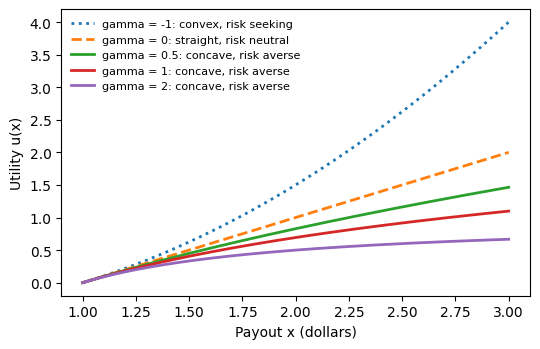

In [15]:
x = np.linspace(1, 3, 200)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for gamma, ls in ((-1, ':'), (0, '--'), (0.5, '-'), (1, '-'), (2, '-')):
    shape = 'convex, risk seeking' if gamma < 0 else 'straight, risk neutral' if gamma == 0 else 'concave, risk averse'
    ax.plot(x, u(x, gamma), ls=ls, lw=2, label=f'gamma = {gamma}: {shape}')
ax.set_xlabel('Payout x (dollars)')
ax.set_ylabel('Utility u(x)')
ax.legend(frameon=False, fontsize=8, loc='upper left')
fig.tight_layout()


The dotted curve ($\gamma = -1$) bends up: each extra dollar adds more utility than the last, so this player likes risk. The dashed line ($\gamma = 0$) is straight: every dollar counts the same. The solid curves bend down, and they bend more as $\gamma$ grows: each extra dollar adds less utility than the last. That bending is what makes a sure amount beat a fair gamble.


Now the coin test as a picture. The gamble pays \$50 or \$150 with equal chance, so its average is $\mathbb{E}(X) = \$100$. The next cell draws three utilities: risk averse ($\gamma = 2$), risk neutral ($\gamma = 0$), and risk seeking ($\gamma = -1$). Each is rescaled so that $u(\$50) = 0$ and $u(\$150) = 1$. Rescaling does not change any choice. It makes all three curves pass through the same two points, so the average utility of the gamble is the same for all three: $\mathbb{E}\,u(X) = 0.5 \times 0 + 0.5 \times 1 = 0.5$.

**Predict:** at $x = \$100$, which curve is above the dotted line at 0.5, and which is below?


Averse  : u(sure $100) = 0.750   E u(gamble) = 0.500
Neutral : u(sure $100) = 0.500   E u(gamble) = 0.500
Seeking : u(sure $100) = 0.375   E u(gamble) = 0.500


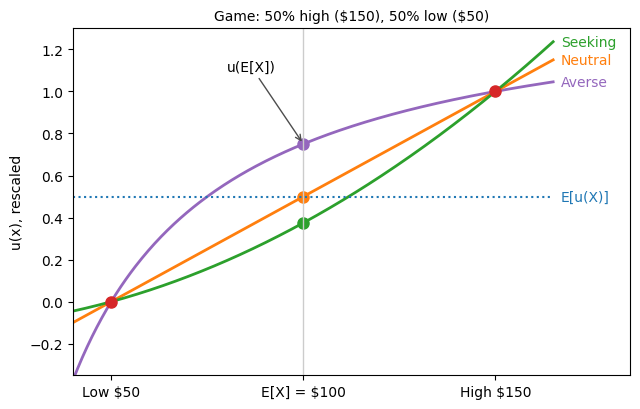

In [16]:
lo_x, hi_x = 50, 150
x = np.linspace(40, 165, 300)

def u_scaled(x, gamma):
    # u rescaled so that u(50) = 0 and u(150) = 1
    return (u(x, gamma) - u(lo_x, gamma)) / (u(hi_x, gamma) - u(lo_x, gamma))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for gamma, name, color in ((2, 'Averse', 'C4'), (0, 'Neutral', 'C1'), (-1, 'Seeking', 'C2')):
    y = u_scaled(x, gamma)
    ax.plot(x, y, color=color, lw=2)
    ax.text(x[-1] + 2, y[-1], name, color=color, va='center', fontsize=10)    # name at the curve's end
    ax.plot(100, u_scaled(100, gamma), 'o', color=color, ms=8)              # u(E[X]), the sure $100
    print(f'{name:8s}: u(sure $100) = {u_scaled(100, gamma):.3f}   E u(gamble) = 0.500')
ax.hlines(0.5, 40, 165, color='C0', ls=':', lw=1.5)
ax.text(167, 0.5, 'E[u(X)]', color='C0', va='center', fontsize=10)
ax.annotate('u(E[X])', xy=(100, 0.75), xytext=(80, 1.1), fontsize=10,
            arrowprops=dict(arrowstyle='->', color='0.3'))
ax.plot([lo_x, hi_x], [0, 1], 'o', color='C3', ms=8)                         # the two outcomes
ax.axvline(100, color='0.8', lw=1)
ax.set_xticks([50, 100, 150])
ax.set_xticklabels(['Low $50', 'E[X] = $100', 'High $150'])
ax.set_ylim(-0.35, 1.3)
ax.set_xlim(40, 185)
ax.set_ylabel('u(x), rescaled')
ax.set_title(r'Game: 50% high (\$150), 50% low (\$50)', fontsize=10)
fig.tight_layout()


At $x = \$100$ the three dots sit at three heights. The dotted line is the utility of the gamble, 0.5, the same for everyone.

- Risk averse: the purple dot is above the line. The sure \$100 has more utility than the gamble: $u(\mathbb{E}X) > \mathbb{E}\,u(X)$.
- Risk neutral: the orange dot is on the line. Sure \$100 and the gamble are equal.
- Risk seeking: the green dot is below the line. The gamble has more utility than the sure \$100: $u(\mathbb{E}X) < \mathbb{E}\,u(X)$.

The reason is the shape. A concave curve lies above the straight line between its two end points, so its middle value beats the average of its ends. A convex curve lies below that line. The certainty equivalent is where a curve crosses the dotted line: left of \$100 for the risk-averse player, right of \$100 for the risk-seeking one.


### Your own $\gamma$

At the start of this section you wrote down the price you would pay to play once. Treat that price as your certainty equivalent. The next cell finds the $\gamma$ whose CE equals your price. A higher price means a smaller $\gamma$: you are less risk averse.

The cell uses $K = 1{,}000$ tosses, so that small values of $\gamma$ are also accurate. Every CE is above \$2, because the game always pays at least \$2. So the price must be above \$2.


In [17]:
def gamma_from_price(price, K=1000):
    # the gamma whose St. Petersburg CE equals price; CE falls as gamma grows
    lo, hi = 0.01, 50.0
    if price <= 2:
        return np.inf                       # no gamma: every CE is above 2 dollars
    if price >= ce_st_petersburg(lo, K):
        return lo                           # very close to risk neutral
    for _ in range(100):                    # bisection on gamma
        mid = (lo + hi) / 2
        if ce_st_petersburg(mid, K) > price:
            lo = mid
        else:
            hi = mid
    return (lo + hi) / 2

my_price = 5                                # change this: the price you wrote down, in dollars
g = gamma_from_price(my_price)
print(f'price ${my_price}: gamma = {g:.2f}, check: CE at this gamma = ${ce_st_petersburg(g, 1000):.2f}')


price $5: gamma = 0.65, check: CE at this gamma = $5.00


A price of \$4 gives $\gamma = 1$, log utility. A price of \$3 gives $\gamma = 2$. Report your $\gamma$ in class.

The next cell does the same for the whole class. Type the prices collected in the room into the list `class_prices`. The cell prints each price with its $\gamma$ and the median $\gamma$ of the class. It then draws the utility curve of each $\gamma$. Each curve is rescaled to go from 0 at \$2 to 1 at \$64, so the curves can be compared on one plot. The dashed straight line is risk neutral. A curve that bends more is more risk averse: it comes from a lower price and a larger $\gamma$.


 price ($)  gamma
         3   2.00
         4   1.00
         5   0.65
        10   0.22
        20   0.09
median gamma of the class: 0.65


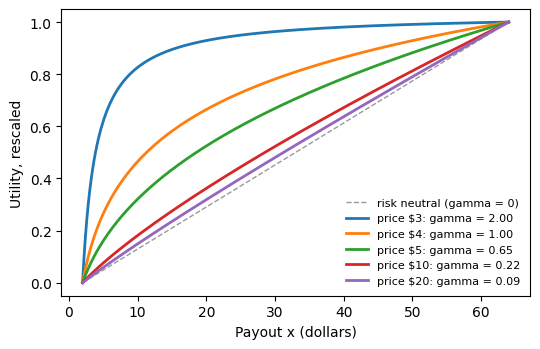

In [18]:
class_prices = [3, 4, 5, 10, 20]            # change this: the prices collected in class, in dollars
gammas = [gamma_from_price(p) for p in class_prices]
print(pd.DataFrame({'price ($)': class_prices, 'gamma': np.round(gammas, 2)}).to_string(index=False))
print(f'median gamma of the class: {np.median(gammas):.2f}')

# utility curves, rescaled so every curve goes from 0 at $2 to 1 at $64
x = np.linspace(2, 64, 300)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(x, (x - 2) / 62, color='0.6', ls='--', lw=1, label='risk neutral (gamma = 0)')
for price, g in zip(class_prices, gammas):
    if np.isfinite(g):
        curve = (u(x, g) - u(2, g)) / (u(64, g) - u(2, g))
        ax.plot(x, curve, lw=2, label=f'price ${price}: gamma = {g:.2f}')
ax.set_xlabel('Payout x (dollars)')
ax.set_ylabel('Utility, rescaled')
ax.legend(frameon=False, fontsize=8, loc='lower right')
fig.tight_layout()


In [19]:
for k in (10, 100, 1023, 1024):
    with np.errstate(over='ignore'):
        print(f'2.0 ** {k:<5} =', np.float64(2.0) ** k)
print('np.exp(709) =', np.exp(709))
with np.errstate(over='ignore'):
    print('np.exp(710) =', np.exp(710))
print('Python integers do not overflow: 2 ** 1024 has', len(str(2 ** 1024)), 'digits')


2.0 ** 10    = 1024.0
2.0 ** 100   = 1.2676506002282294e+30
2.0 ** 1023  = 8.98846567431158e+307
2.0 ** 1024  = inf
np.exp(709) = 8.218407461554972e+307
np.exp(710) = inf
Python integers do not overflow: 2 ** 1024 has 309 digits


`2.0 ** 1023` is a number with 308 digits, and `2.0 ** 1024` is `inf`. We stop the St. Petersburg sum at $K = 200$ because 200 terms are enough for the convergent cases we report (for example $\gamma = 1$ and $\gamma = 2$). For $\gamma = 0$ or below they are only partial sums of a divergent sum, and a small positive $\gamma$ can converge slowly. Separately, past about toss 1023 the number `2.0 ** T` becomes `inf`, so a sum that went that far would break. In `np.exp`, the limit is 709. A Python integer has no limit, but you cannot mix it with floats for large values.

In practice: keep the log of any number that can be huge or tiny (a bankroll, a likelihood, a probability of a long sequence), and exponentiate only at the end, if at all.

### Check yourself

1. A risk-averse player and a risk-neutral player are offered a fair coin: win \$10 or lose \$10. Which one takes it?
2. Under log utility, a player with \$100 is offered a fair bet to win or lose \$50. Does he take it? Compute $\log$ of his wealth in the two cases.
3. Why does the St. Petersburg game have an infinite average payout and a finite CE?

<details><summary>Answer</summary>

1. The risk-neutral player is indifferent. The risk-averse player refuses: the fair bet has the same average as no bet, and a concave utility values the average of utilities lower than the utility of the average.
2. The average utility of the bet is $\tfrac12 \log 50 + \tfrac12 \log 150 = \tfrac12 (3.912 + 5.011) = 4.461$. The utility of keeping the \$100 is $\log 100 = 4.605$. Since $4.461 < 4.605$ he refuses. The CE of the bet is $e^{4.461} = \$86.6$.
3. The huge payouts have tiny chances. The average counts payout times chance, which is \$1 for every toss, and adds infinitely many. Utility weights a big payout much less than its size, so the terms shrink fast and the sum is finite.

</details>


### Exercise 8.1 (In class)

The St. Petersburg game pays $2^T$ dollars when the first head is on toss $T$, with chance $2^{-T}$. A player has log utility, $u(x) = \log x$.

Add the first 200 tosses ($T = 1, \ldots, 200$). Compute the expected log utility, the sum over $T$ of $2^{-T} \log(2^T)$. Define `ce_log` as the exponential of that sum: the certainty equivalent of the game for this player, in dollars. The answer is one number.


In [20]:
# Exercise 8.1: define ce_log
ce_log = None


In [21]:
# check("ce_log", ce_log, "5f40042b4406c45e")
# print("ok  8.1")


## 2. Kelly: the best share of the bankroll to bet

Section 1 valued a risky payout by the average of its log. Kelly's rule uses the same idea for repeated bets. Suppose you bet again and again, each time a fixed share of your bankroll, the money you set aside for betting. Each bet multiplies the bankroll by a number. The Kelly share is the share that maximizes the average log of that number. It makes the bankroll grow fastest over many bets.

**The bet.** A bet pays $O = 3.5$ for each \$1 staked, the \$1 stake included. A winning \$1 ticket pays back \$3.50: the \$1 stake plus \$2.50 profit. The bet wins with chance $c = 0.32$. **The chance 0.32 is made up for this section.** Section 3 shows where a chance like it would come from.

The bet makes money on average only if $c$ is above the break-even chance $1/O = 1/3.5 = 0.286$. Here $c = 0.32$ is above it.

The **edge** is the expected profit on a \$1 bet. A ticket earns $O - 1$ with chance $c$ and loses the \$1 with chance $1 - c$:

$$
\text{edge} = c\,(O - 1) - (1 - c) = cO - 1.
$$

Before you run the cell, compute the edge by hand.


In [22]:
c_bet = 0.32   # made up for this section
O_bet = 3.5
edge_bet = c_bet * O_bet - 1
print(f'edge = {c_bet} x {O_bet} - 1 = {edge_bet:.3f}')


edge = 0.32 x 3.5 - 1 = 0.120


The edge is 0.120: on average, each \$1 bet makes 12 cents. The edge says the bet is worth making. It does not say how much to bet.

The Kelly rule gives the share $f$ of the bankroll to bet:

$$
f = \frac{\text{edge}}{O - 1} = \frac{cO - 1}{O - 1}.
$$

In words: divide the edge by $O - 1$, the profit on a winning \$1 ticket. If the edge is 0 or below, $f = 0$ and you do not bet. Betting exactly this share is called full Kelly.

**Where the formula comes from.** Write $b = O - 1$ for the profit on a winning \$1. You bet the share $f$ of your bankroll $W$.

- If the horse wins (chance $c$), the bankroll becomes $W(1 + bf)$.
- If it loses (chance $1 - c$), the bankroll becomes $W(1 - f)$.

Use log utility from Section 1. The expected log of the bankroll is

$$
\mathbb{E}\log(\text{bankroll}) = \log W + c\,\log(1 + bf) + (1 - c)\,\log(1 - f).
$$

The term $\log W$ does not depend on $f$. To find the best $f$, set the derivative with respect to $f$ to zero:

$$
\frac{cb}{1 + bf} - \frac{1 - c}{1 - f} = 0.
$$

Multiply both sides by $(1 + bf)(1 - f)$:

$$
cb\,(1 - f) = (1 - c)(1 + bf).
$$

Expand: $cb - cbf = 1 - c + bf - cbf$. The $cbf$ terms cancel, so $cb - (1 - c) = bf$, and

$$
f = \frac{cb - (1 - c)}{b} = \frac{c(O - 1) - (1 - c)}{O - 1} = \frac{cO - 1}{O - 1}.
$$

So the Kelly share is the bet that a person with log utility would choose. The growth curve below shows why it is the best share: it is the peak.

The same rule appears with other names. Chapter 4 writes $f^\star = (bp - (1-p))/b$, with $b = O - 1$ for the profit on a win, $p = c$ for the chance, and $f^\star$ for $f$. Benter's paper (Section 3) says "advantage" for the edge and "dividend" for $O$, and writes the rule as advantage divided by (dividend minus 1).

Before you run the cell, compute $0.120 / 2.5$ by hand.


In [23]:
f_bet = edge_bet / (O_bet - 1)
print(f'Kelly fraction f = {edge_bet:.3f} / {O_bet - 1} = {f_bet:.3f}')


Kelly fraction f = 0.120 / 2.5 = 0.048


$f = 0.048$. Full Kelly bets 4.8% of the bankroll.

Say the bankroll is \$10,000. Full Kelly bets 4.8% of \$10,000, which is \$480.

Most professional bettors bet less than full Kelly, because $c$ is only an estimate. Kelly is right only when $c$ is right, and a bet that is too large loses money over time even when the edge is positive. A common choice is half Kelly: half of \$480, which is \$240.

The next cell shows why half Kelly is safer. Picture the same bet 1,000 times: payout $O = 3.5$, the same chance of winning each time, and each time he stakes the same share $f$ of whatever his bankroll is then. A win multiplies the bankroll by $1 + (O-1)f$. A loss multiplies it by $1 - f$. The share $f$ comes from your chance $c = 0.32$, but the bet wins with its true chance, $c_{\text{true}}$, which may be different. The growth per bet is the average log of the two multipliers:

$$
g(f) = c_{\text{true}}\,\log\bigl(1 + (O-1)f\bigr) + (1-c_{\text{true}})\,\log(1 - f).
$$

When $g$ is above 0 the bankroll grows over many bets. When $g$ is below 0 it shrinks. After $n$ bets a typical bankroll is the starting bankroll times $e^{ng}$: about half of all bettors end above it and half below. The cell prints $g$ and the typical bankroll after 1,000 bets, for full and for half Kelly, in two cases. In the first, $c_{\text{true}} = 0.32$, as you think. In the second, $c_{\text{true}} = 0.30$, two points lower.


In [24]:
bankroll = 10_000
full, half = f_bet, f_bet / 2
print(f'full Kelly: {full:.3f} x ${bankroll:,} = ${full * bankroll:,.0f}')
print(f'half Kelly: {half:.3f} x ${bankroll:,} = ${half * bankroll:,.0f}')
print()

def growth(f, c, O):
    # growth of the bankroll per bet, on the log scale
    return c * np.log(1 + (O - 1) * f) + (1 - c) * np.log(1 - f)

for c_true in (0.32, 0.30):
    for name, f in (('full', full), ('half', half)):
        g = growth(f, c_true, O_bet)  # f comes from c = 0.32; the bet wins with c_true
        typical = bankroll * np.exp(1000 * g)
        print(f'true chance {c_true:.2f}, {name} Kelly: g = {g:+.5f}, '
              f'typical bankroll after 1,000 bets ${typical:,.0f}')


full Kelly: 0.048 x $10,000 = $480
half Kelly: 0.024 x $10,000 = $240

true chance 0.32, full Kelly: g = +0.00282, typical bankroll after 1,000 bets $167,068
true chance 0.32, half Kelly: g = +0.00213, typical bankroll after 1,000 bets $83,898
true chance 0.30, full Kelly: g = -0.00043, typical bankroll after 1,000 bets $6,475
true chance 0.30, half Kelly: g = +0.00048, typical bankroll after 1,000 bets $16,093


If the chance 0.32 is right, full Kelly is best: a typical \$10,000 grows to about \$167,000 after 1,000 bets, against about \$84,000 at half Kelly. If the true chance is 0.30, the edge is still positive (0.05), but full Kelly now bets too much, and the typical bankroll falls to about \$6,500. Half Kelly still grows it, to about \$16,000.

So a mistake of two points in $c$ turns full Kelly from the best choice into a losing one. Half Kelly gives up some growth when $c$ is right, and keeps the bankroll growing when $c$ is a little too high. Benter's paper (Section 3) makes the same point: if you overestimate the edge by more than a factor of two, full Kelly can make the bankroll shrink. Here the edge is overestimated 2.4 times: 0.12 against 0.05.

The plot below draws $g(f)$ for both true chances. The dotted lines mark half and full Kelly.

Kelly, and every rule in this lab, only works if the probability is calibrated: among events given probability $p$, about a fraction $p$ should happen. The [Calibration Lab](https://vsokolov.org/labs/calibration-lab.html) shows a model whose numbers between 0 and 1 are not probabilities, on the same 1/5 lending rule as the credit example.


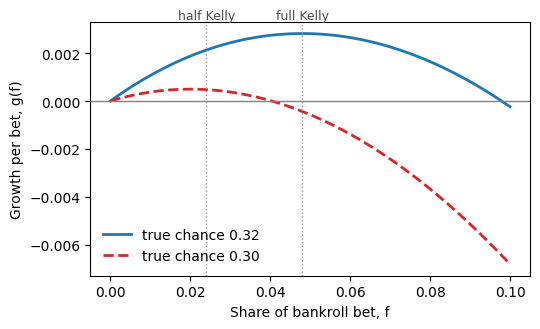

In [25]:
grid = np.linspace(0, 0.1, 200)
fig, ax = plt.subplots(figsize=(5.5, 3.4))
for c_true, color, ls in ((0.32, 'C0', '-'), (0.30, 'C3', '--')):
    ax.plot(grid, growth(grid, c_true, O_bet), color=color, ls=ls, lw=2,
            label=f'true chance {c_true:.2f}')
ax.axhline(0, color='0.5', lw=1)
top = ax.get_ylim()[1]
for f, name in ((half, 'half Kelly'), (full, 'full Kelly')):
    ax.axvline(f, color='0.6', ls=':', lw=1)
    ax.text(f, top, name, ha='center', va='bottom', fontsize=9, color='0.3')
ax.set_xlabel('Share of bankroll bet, f')
ax.set_ylabel('Growth per bet, g(f)')
ax.legend(frameon=False, loc='lower left')
fig.tight_layout()


Each curve rises to a peak and then falls. The peak is the best share for that true chance: 0.048 when the chance is 0.32, and 0.020 when it is 0.30. Past the peak, betting more makes the bankroll grow more slowly, and where a curve drops below 0 the bankroll shrinks. The red dashed curve ($c_{\text{true}} = 0.30$) drops below 0 at $f = 0.040$, so full Kelly (0.048) is already in the losing zone. Half Kelly (0.024) is above 0 on both the blue solid curve ($c_{\text{true}} = 0.32$) and the red dashed one.


### Simulating many bettors

The growth per bet $g(f)$ is an average. To see what it means for real bankrolls, simulate it. Start with a bankroll of \$10,000. Each bet multiplies it by a number: $1 + (O-1)f$ after a win and $1 - f$ after a loss. After $n$ bets the bankroll is the start times the product of $n$ multipliers. Taking logs turns the product into a sum, so the growth per bet is the average of the log multipliers. That average is $g(f)$ above. Kelly is the $f$ at the peak of $g$. We write $f^\star$ for this full-Kelly share, $f^\star = (cO - 1)/(O - 1) = 0.048$. Half Kelly is $0.5 f^\star$ and twice Kelly is $2 f^\star$.

We use the bet of this section: $O = 3.5$, and a true chance of winning $c_{\text{true}} = 0.32$ (made up). The bettor also uses $c = 0.32$ to set $f^\star$, so $c = c_{\text{true}}$ here. We simulate 1,000 independent betting histories of 1,000 bets each. For each history, we compare half, full, and twice Kelly using the **same** outcomes. This makes the comparison fair: the only difference is the share $f$.


**Predict:** at twice Kelly ($2f^\star$), what is the median bankroll after 1,000 bets? Is it above or below the \$10,000 start?


In [26]:
rng = np.random.default_rng(8)
n_bettors, n_bets = 1000, 1000
start = 10_000
wins = rng.random((n_bettors, n_bets)) < c_bet      # True when the bet wins; the same flips for every share
log_paths = {}                                   # log of the bankroll after each bet
rows = []
for mult in (0.5, 1, 2):
    f_s = mult * f_bet
    log_mult = np.where(wins, np.log1p((O_bet - 1) * f_s), np.log1p(-f_s))   # log of each multiplier
    log_paths[mult] = np.log(start) + np.cumsum(log_mult, axis=1)     # sum of logs, not a product
    final = np.exp(log_paths[mult][:, -1])
    rows.append({'share of Kelly': mult, 'f': round(f_s, 3),
                 'g(f)': round(growth(f_s, c_bet, O_bet), 5),
                 'median final': round(np.median(final)),
                 'mean final': round(final.mean()),
                 'best bettor': round(final.max()),
                 'share below start': round((final < start).mean(), 3)})
pd.DataFrame(rows).set_index('share of Kelly')


,f,g(f),median final,mean final,best bettor,share below start
share of Kelly,,,,,,
0.5,0.024,0.00213,83898,166186,2476571,0.037
1.0,0.048,0.00282,167068,1996386,130832669,0.108
2.0,0.096,0.00021,12288,23310791,5210212270,0.485


Medians after 1,000 bets, from \$10,000: about \$83,898 at half Kelly, \$167,068 at full Kelly, and \$12,288 at twice Kelly. These match the typical bankrolls computed from $g$ above (\$84,000 and \$167,000). Twice Kelly ends only a little above the start, because its growth $g(2f^\star) = 0.00021$ is almost 0. Of the twice-Kelly bettors, 48.5% (nearly half) ended below \$10,000. At full Kelly that share is 10.8%, and at half Kelly 3.7%.

Look at the **mean** at full Kelly: \$1,996,386, far above the median \$167,068. A few lucky bettors pull the mean up (the best one ends with \$130,832,669). The median is what a typical bettor gets. This is why Kelly is judged by the growth rate $g$, not by the mean.

The plot shows the median bankroll after each bet, on a log scale.


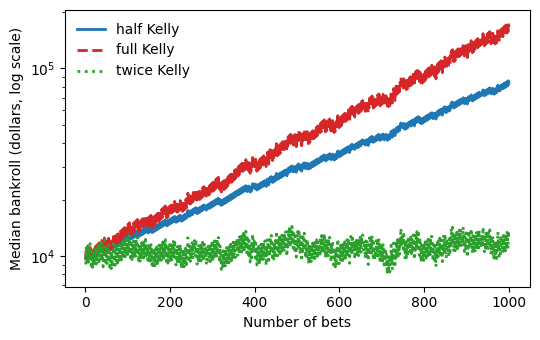

In [27]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
styles = {0.5: ('C0', '-', 'half Kelly'), 1: ('C3', '--', 'full Kelly'), 2: ('C2', ':', 'twice Kelly')}
for mult, (color, ls, label) in styles.items():
    ax.plot(np.arange(1, n_bets + 1), np.exp(np.median(log_paths[mult], axis=0)), color=color, ls=ls, lw=2, label=label)
ax.set_yscale('log')
ax.set_xlabel('Number of bets')
ax.set_ylabel('Median bankroll (dollars, log scale)')
ax.legend(frameon=False)
fig.tight_layout()


Full Kelly (red dashed) climbs fastest. Half Kelly (blue solid) climbs about three quarters as steeply as full Kelly on this log scale ($g = 0.00213$ against $0.00282$). On the dollar scale its final median is about half as large (\$84,000 against \$167,000). Twice Kelly (green dotted) goes nowhere: past a point, betting more makes the growth smaller, and at twice Kelly it is back to about 0 ($g = 0.00021$).

**Your turn.** The bettor stakes $f^\star = 0.048$, computed from the chance 0.32. Suppose the true chance of the bet is lower. The cell prints the growth $g$ at that same share for six true chances. Target: name the smallest true chance in the list for which the cell prints "grows". Then add values between it and the next smaller value in the list, to find the smallest chance to three decimals.


In [28]:
for c_try in (0.32, 0.315, 0.31, 0.305, 0.30, 0.295):  # change this: try other true chances
    g = growth(f_bet, c_try, O_bet)
    print(f'true chance {c_try:.3f}: g = {g:+.5f}  ', 'grows' if g > 0 else 'shrinks')


true chance 0.320: g = +0.00282   grows
true chance 0.315: g = +0.00200   grows
true chance 0.310: g = +0.00119   grows
true chance 0.305: g = +0.00038   grows
true chance 0.300: g = -0.00043   shrinks
true chance 0.295: g = -0.00125   shrinks


### Computing corner: why we add logs

A bankroll after 1,000 bets is a product of 1,000 numbers. Computers store a `float64` with about 16 digits, and its size has limits. The next cell prints them. Then it multiplies 1,000 multipliers of 3 (a bettor who triples his money every time), and 1,000 multipliers of 0.3.


In [29]:
info = np.finfo(np.float64)
print('largest float64 :', info.max)
print('smallest normal float64:', info.tiny)
print('eps (smallest relative step):', info.eps)
print()
with np.errstate(over='ignore'):
    print('product of 1,000 threes   :', np.prod(np.full(1000, 3.0)))
    print('product of 1,000 times 0.3:', np.prod(np.full(1000, 0.3)))
    print('np.exp(1000)              :', np.exp(1000))
print('sum of logs of the threes :', round(np.sum(np.log(np.full(1000, 3.0))), 1))
print('so the product is 10 to the', round(np.sum(np.log10(np.full(1000, 3.0))), 1))
print()
print('np.log(1 + 1e-20) =', np.log(1 + 1e-20))
print('np.log1p(1e-20)   =', np.log1p(1e-20))


largest float64 : 1.7976931348623157e+308
smallest normal float64: 2.2250738585072014e-308
eps (smallest relative step): 2.220446049250313e-16

product of 1,000 threes   : inf
product of 1,000 times 0.3: 0.0
np.exp(1000)              : inf
sum of logs of the threes : 1098.6
so the product is 10 to the 477.1

np.log(1 + 1e-20) = 0.0
np.log1p(1e-20)   = 1e-20


The largest `float64` is about 1.8e+308. The product of 1,000 threes is $3^{1000}$, about 10 to the power 477. That is too big, so the computer prints `inf`. The product of 1,000 times 0.3 is too small, and it prints `0.0` (underflow). `np.exp(1000)` is `inf` for the same reason. Both answers are wrong, but the *sum of logs* is fine: 1098.6, a normal number. So we keep the log of the bankroll, as in the simulation above, and add log multipliers instead of multiplying multipliers.

The last two lines are a second trap. $\varepsilon$ = 2.2e-16 is the smallest relative step the computer can see. Adding $10^{-20}$ to 1 is below that step, so the sum stays exactly 1, and `np.log(1 + 1e-20)` is 0. `np.log1p(x)` computes $\log(1+x)$ without that rounding. We used it above for the multipliers.

**Check yourself**

1. A bettor stakes $f = 0.10$ on a bet with $O = 5$. What are his two multipliers, and what is the growth per bet if $c = 0.25$?
2. Why does half Kelly give up some growth when $c$ is right, but protect you when $c$ is a little too high?

<details><summary>Answer</summary>

1. A win multiplies the bankroll by $1 + 4 \times 0.10 = 1.4$. A loss multiplies it by $0.9$. The edge is $0.25 \times 5 - 1 = 0.25$, so $f^\star = 0.25/4 = 0.0625$, and $f = 0.10$ is above Kelly. The growth is $0.25 \log 1.4 + 0.75 \log 0.9 \approx 0.0841 - 0.0790 = 0.0051$, still above 0 but below the peak.
2. Growth $g$ has a peak at $f^\star$ and falls on both sides. At half Kelly you bet less, so you give up some growth when $c$ is right. But $c$ is only an estimate, and you do not know where the true peak is. Betting less keeps you away from the overbetting side if $c$ is too high. It does not guarantee positive growth: if $c$ is far too high, even half Kelly can shrink the bankroll.

</details>


### Exercise 8.2 (In class)

A bet has payout $O = 5$: a winning \$1 ticket pays back \$5, the \$1 included. Your chance of winning is $c = 0.28$. Your bankroll is \$8,000.

Define `stake_half`: the dollar stake at **half** Kelly, using $f = (cO - 1)/(O - 1)$. The answer is one number (dollars).


In [30]:
# Exercise 8.2: define stake_half
stake_half = None


In [31]:
check("stake_half", stake_half, "fe1b60fe1b69643b")
print("ok  8.2")


AssertionError: stake_half is still None: fill in the exercise cell above and run it

## 3. Benter: from the payout board to a dollar stake

Bill Benter made a fortune betting on horse races in Hong Kong. Before each race he answered two questions: which horse to bet on, and how many dollars to bet. This section follows his recipe through one real race, one step at a time. The rule for how many dollars is the Kelly rule of Section 2.

This section uses one real race. In that race Benter does not bet: no horse has a positive edge. Step 6 then uses a made-up chance for horse 3. That is the bet that Section 2 sized.

The symbols, with their values for horse 3:

| Symbol | In plain words | Real race (Steps 1 to 5) | Made-up example (Step 6) |
|---|---|---|---|
| $O$ | The payout on the board: what a winning \$1 ticket pays back, the \$1 included | 3.5 | 3.5 |
| $O - 1$ | The profit on a winning \$1 ticket | 2.5 | 2.5 |
| $1/O$ | The break-even chance: the bet makes money on average only if the horse wins more often than this | 0.286 | 0.286 |
| $q$ | The crowd's chance that the horse wins, read from the payouts | 0.234 | 0.234 |
| $c$ | Benter's chance that the horse wins | 0.244 | 0.32 |
| $cO - 1$ | The edge: the expected profit on a \$1 bet | $-0.147$ | 0.120 |
| $f$ | The share of his bankroll that he bets (Section 2) | 0 (no bet) | 0.048 |

The symbols $c$ and $cO - 1$ are explained in Steps 4 and 5 of the recipe below. The code uses the unrounded chance $c = 0.2438$ for horse 3. Hand arithmetic with the rounded 0.244 can differ in the last digit (the edge is $-0.146$ by hand and $-0.147$ in the code).

How the crowd's chance $q$ is calculated, for horse 3 (the recipe's Steps 1 to 3 below do the same for every horse):

- (a) Take $1/O$ for each horse. Horse 3: $1/3.5 = 0.286$.
- (b) Add up $1/O$ over all ten horses in the race. Here the sum is 1.2234. It is more than 1 because the track keeps a cut of every dollar bet (recipe Step 2).
- (c) Divide each horse's $1/O$ by that sum. Horse 3: $q = 0.286 / 1.2234 = 0.234$.

$$
q = \frac{1/O}{\sum_{\text{all horses in the race}} 1/O}.
$$

After step 3 the ten values of $q$ add up to 1, so they can be read as chances.

The recipe has seven steps.

1. Read the payout board.
2. Measure the track's cut.
3. Turn the payouts into the crowd's chances $q$.
4. Correct the crowd's chances. The result is Benter's chances $c$.
5. Test each horse. Bet only if the edge $cO - 1$ is above 0.
6. A what-if: a horse that passes the test. Its bet is the one sized in Section 2.
7. Put the whole recipe in one function.

**Online lab:** open the [Benter Betting Lab](https://vsokolov.org/labs/benter-lab.html) next to this section. Try: change the payout of one horse and watch its stake appear and vanish. The lab uses $1/O$ and $\log q$, as this notebook does.


### One race, from the payout board to a dollar amount

#### Step 1. Read the payout board

Race 1159 ran at Happy Valley on 25 November 1998, with ten horses. The next cell types in the final payouts $O$ from the board. Horse 3 has the lowest payout, 3.5, so it is the crowd's favorite. A winning \$1 ticket on horse 3 pays back \$3.50: the \$1 stake plus \$2.50 profit.

Racetracks call $O$ the odds, but it is not the odds $p/(1-p)$; this lab calls it the payout.

The break-even chance is $1/O$. For horse 3 it is $1/3.5 = 2/7 = 0.286$. Check: a \$1 bet that earns \$2.50 with chance $2/7$ and loses the \$1 with chance $5/7$ has expected profit $\tfrac{2}{7} \times 2.50 - \tfrac{5}{7} \times 1 = \tfrac{5}{7} - \tfrac{5}{7} = 0$.


In [ ]:
race = pd.DataFrame({
    'horse': range(1, 11),
    'O': [8.1, 9.5, 3.5, 19.0, 9.7, 13.0, 6.0, 6.2, 14.0, 13.0],
})
race['break_even'] = 1 / race.O
race.round(3)


Horse 3 breaks even at 0.286. The longest shot, horse 4 at payout 19.0, breaks even at 0.053.

#### Step 2. Measure the track's cut

Add up the break-even chances of all ten horses. If the track kept nothing, the sum would be exactly 1. It is above 1, because the track keeps a share of every dollar bet, the cut, and pays only the rest, $1 - \text{cut}$, to the winners. That makes every payout $O$ smaller by the factor $1 - \text{cut}$, so every $1/O$ is larger by the factor $1/(1 - \text{cut})$, and so is their sum: $\sum 1/O = 1/(1 - \text{cut})$. Solve for the cut:

$$
\text{cut} = 1 - \frac{1}{\sum 1/O}.
$$


In [ ]:
total = race.break_even.sum()
cut = 1 - 1 / total
print(f'sum of 1/O = {total:.4f}')
print(f'track cut  = {cut:.3f}')


The sum is 1.2234, so the cut is 0.183. Of every \$1 bet on this race, the track kept about 18 cents and paid about 82 cents to the winning tickets. The Hong Kong Jockey Club deducts 17.5% from the win pool, close to this.

#### Step 3. Turn the payouts into the crowd's chances

The break-even chances add to 1.2234, so they are not chances yet. The cut made every one of them larger by the same factor, so dividing each by the sum removes the cut. The results add to 1, and they are the crowd's chances $q$:

$$
q = \frac{1/O}{\sum 1/O}.
$$

Before you run the cell, predict $q \times O$ for horse 3. Hint: $q \times O = \frac{1/O}{\sum 1/O} \times O = \frac{1}{\sum 1/O}$, the same number for every horse.


In [ ]:
race['q'] = race.break_even / total
race['q_times_O'] = race.q * race.O
print(f'sum of q = {race.q.sum():.3f}')
race.round(3)


Horse 3 has $q = 0.234$. The crowd gives it about a 23% chance, below the 28.6% it needs to break even. The column `q_times_O` is 0.817 for every horse, and $0.817 = 1 - \text{cut}$. In words: if the crowd's chances are right, every \$1 bet in this race pays back 82 cents on average, whichever horse you pick. To make money on a horse, Benter's chance $c$ must be above its break-even chance $1/O$, which is $q / (1 - \text{cut})$. For horse 3 that is $0.234 / 0.817 = 0.286$.

#### Step 4. Correct the crowd's chances

The crowd is good but not perfect. Favorites win a little more often than the crowd's chance says, and longshots a little less often. Benter's simplest correction raises every crowd chance to one power $\alpha$, then rescales so the ten chances add to 1 again:

$$
c = \frac{q^{\alpha}}{\sum q^{\alpha}}.
$$

With $\alpha = 1$ nothing changes, and $c = q$. With $\alpha$ above 1, the horses with the highest chances gain a little and the rest lose a little. Since $q^{\alpha} = e^{\alpha \log q}$, this is the softmax function from the logistic regression notebook, with scores $\alpha \log q$.

The value $\alpha = 1.06$ was fitted by maximum likelihood on the Hong Kong races in the data of Chapter 13: 5,885 races, minus 12 dead heats with two winners, leaves 5,873. Maximum likelihood picks the $\alpha$ that makes the actual winners most likely: it maximizes the product, over all races, of $c$ for the horse that won. The race files are not in this notebook, so the next cell types the value in.

Section 2 of the online [Benter betting lab](https://vsokolov.org/labs/benter-lab.html) fits the same correction on all the races. Drag $\alpha$ there and watch the likelihood change.


In [ ]:
alpha = 1.06
race['c'] = race.q**alpha / (race.q**alpha).sum()
race[['horse', 'O', 'break_even', 'q', 'c']].round(3)


Horse 3 goes from $q = 0.234$ to $c = 0.244$. Horse 4, the longest shot, goes from 0.043 to 0.041. The changes are small: one percentage point for the favorite. The code keeps the unrounded $c$ (0.2438 for horse 3), not 0.244.

#### Step 5. Test each horse: is the edge above 0?

The edge is the expected profit on a \$1 bet, computed with Benter's chance $c$. The ticket earns $O - 1$ with chance $c$ and loses the \$1 with chance $1 - c$:

$$
\text{edge} = c\,(O - 1) - (1 - c) = cO - 1.
$$

He bets on a horse only if its edge is above 0. That is the same as $c > 1/O$: his chance must beat the break-even chance from Step 1.


In [ ]:
race['edge'] = race.c * race.O - 1
race[['horse', 'O', 'break_even', 'c', 'edge']].round(3)


Every edge is negative. The best one is horse 3's, $-0.147$: a \$1 bet on horse 3 loses about 15 cents on average. Horse 3 needs $c$ above 0.286 and has 0.244, so it is 4.2 percentage points short. By hand with 0.244 the edge is $-0.146$. The code keeps more digits ($c = 0.2438$), which gives $-0.147$. **Benter does not bet on this race.**

This is the usual answer. Over all 5,885 races in the Hong Kong data of Chapter 13, the correction of Step 4 finds no bet at all, apart from 30 races whose recorded payouts are wrong: in those races the cut computed as in Step 2 is under 4%, instead of about 18%. A small correction of the crowd cannot beat an 18% cut. Benter beat it with a much richer model: more than a hundred facts about each horse, combined with the crowd's chance.

#### Step 6. A what-if: a horse that passes the test

We do not have Benter's full model. To see a bet that passes the test, suppose his full model gives horse 3 the chance $c = 0.32$, and lowers the other nine horses so the ten chances still add to 1. **The number 0.32 is made up for this example. It is not from the data.**

Now $c = 0.32$ is above the break-even chance 0.286, so the edge is positive: $0.32 \times 3.5 - 1 = 0.120$. The other nine horses failed the test in Step 5 and are now lower still, so horse 3 is the only bet in this race.

This is the bet from Section 2: payout 3.5, chance 0.32, edge 0.120, full Kelly $f = 0.048$. On a bankroll of \$10,000, full Kelly stakes \$480 and half Kelly stakes \$240. Benter stakes half Kelly, for the reason given in Section 2: $c$ is only an estimate.

How the race ended: horse 3 lost, and horse 8 won. In the what-if, Benter loses the \$240, and his bankroll is now \$9,760. His next stake is a share of \$9,760, not of \$10,000. A good bet can lose. The edge shows up only over many races.


#### Step 7. Put the whole recipe in one function

Step 5 and the Kelly rule of Section 2 fit in a few lines. The function takes the payout $O$, Benter's chance $c$, the bankroll, and the share of Kelly he uses (half, unless you say otherwise).

**Predict:** what stake does `benter_stake(3.5, 0.32, 10_000)` return? Use the numbers of Step 6, then run the cell.


In [ ]:
def benter_stake(O, c, bankroll, share=0.5):
    edge = c * O - 1             # Step 5: expected profit on a $1 bet
    if edge <= 0:
        return 0.0               # no edge, no bet
    f = edge / (O - 1)           # Section 2: the Kelly fraction
    return share * f * bankroll  # Section 2: dollars, at half Kelly unless told otherwise

c_step4 = race.loc[race.horse == 3, 'c'].item()
print(f'Step 4 chance {c_step4:.3f}: stake ${benter_stake(3.5, c_step4, 10_000):,.0f}')
print(f'Step 6 chance {0.32:.3f}: stake ${benter_stake(3.5, 0.32, 10_000):,.0f}')


With Step 4's chance the stake is \$0: no bet. With Step 6's what-if chance it is \$240.

#### Your turn

1. Run `benter_stake` with $O = 3.5$ and $c = 0.30$, then with $c = 0.28$. Below which value of $c$ is the stake \$0? It is the break-even chance $1/O$ from Step 1.
2. Chapter 4 has two bets given as profit odds. The profit odds 4/1 mean a winning \$1 earns \$4 profit (this is not $p/(1-p)$), so the payout is $O = 5$. The profit odds 12/1 mean $O = 13$. Before you run the second cell below, compute by hand the edge and the full Kelly fraction for 4/1 at $c = 1/4$ and for 12/1 at $c = 1/10$.


In [ ]:
# Your turn: the stake at c = 0.30 and c = 0.28.
for c_try in (0.30, 0.28):  # change this: add more values of c
    print(f'c = {c_try:.2f}: stake ${benter_stake(3.5, c_try, 10_000):,.0f}')


In [ ]:
for O, c in ((5, 1/4), (13, 1/10)):
    edge = c * O - 1
    print(f'O = {O}, c = {c:.2f}: edge = {edge:.2f}, full Kelly f = {edge / (O - 1):.4f}')


The 4/1 bet has edge 0.25 and $f = 0.0625$, which is 1/16 of the bankroll. The 12/1 bet has the larger edge, 0.30, yet $f = 0.025$, which is 1/40, two and a half times less. Kelly divides the edge by the profit on a win, and the 12/1 horse loses 9 races in 10, so Kelly bets less on it.

What the recipe leaves out:

- In Hong Kong the payouts come from the bets themselves (a pari-mutuel pool), so Benter's own money lowered the payout he was paid. His large bets had to be smaller than the formula says.
- When two or more horses in one race pass the test, their stakes are found together. Section 5 of the online [Benter betting lab](https://vsokolov.org/labs/benter-lab.html) does this.
- The payouts keep changing until the race starts, so the bet is placed before the final payouts are known.


## 4. Benter on 40 years of Hong Kong races

Section 3 followed one race. This section uses all of them. The data are real: Hong Kong races from 1979 to 2018, one row per horse per race. Every fact about a horse was known before the race. The first time you run the next cell it downloads the file `hk_features.csv.gz` (18 MB) from the course site.

The steps:

1. Load the data and drop the races with wrong payouts.
2. Check whether the crowd's chances $q$ are right.
3. Fit the exponent $\alpha$ of Section 3, Step 4.
4. Add one fact about the horse: its post position, the starting gate it is given.
5. Test the model on seasons it has not seen.
6. Your turn.

#### Step 1. Load the data and drop the wrong payouts

The column `odds` is the payout $O$. The column `q_public` is the crowd's chance $q$, computed as in Section 3. The next cell computes the cut of each race with the formula of Section 3, $\text{cut} = 1 - 1/\sum (1/O)$. A cut far from the usual 18% means that the recorded payouts of that race are wrong. The cell drops every race whose cut is outside 0.10 to 0.25.


In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

from scipy.optimize import minimize

DATA = Path("data")
DATA.mkdir(exist_ok=True)
path = DATA / "hk_features.csv.gz"
if not path.exists():
    urlretrieve("https://vsokolov.org/courses/files/600/data/hk_features.csv.gz", path)

hk = pd.read_csv(path)
print(f"{len(hk):,} horses in {hk.race_key.nunique():,} races, "
      f"{hk.date.min()[:4]} to {hk.date.max()[:4]}")

# the cut of each race, with the formula of Section 3
hk['cut'] = 1 - 1 / (1 / hk.odds).groupby(hk.race_key).transform('sum')
print(hk.groupby('race_key').cut.first().describe().round(3))

wrong = hk.groupby('race_key').cut.first().pipe(lambda c: (c <= 0.10) | (c >= 0.25))
print(f"races with a cut outside 0.10 to 0.25: {wrong.sum():,}")
hk = hk[hk.race_key.isin(wrong.index[~wrong])].sort_values('race_key').reset_index(drop=True)
print(f"kept: {hk.race_key.nunique():,} races, {len(hk):,} horses, "
      f"{hk.groupby('race_key').won.sum().unique()} winner(s) per race")


The file has 265,512 rows, one for each horse, in 22,979 races. The median cut is 0.185, close to the 0.183 of race 1159 in Section 3. The smallest cut is a negative number, which is impossible, so some races have wrong payouts. There are 1,853 races with a cut outside 0.10 to 0.25. We drop them. That leaves 21,126 races and 247,792 horses, with exactly one winner in each race.


#### Step 2. Is the crowd right?

If the crowd's chances are right, then among all horses with $q$ near 0.10, about 10% win. The next cell sorts all the horses into ten bins of equal size by $q$. For each bin it prints the average $q$ and the share of the horses that won. The plot has the same numbers on a log scale. The dashed line is where the crowd is exactly right.

**Predict:** do the dots lie on the dashed line, above it, or below it?


In [ ]:
hk['bin'] = pd.qcut(hk.q_public, 10, labels=False)
cal = hk.groupby('bin').agg(q=('q_public', 'mean'), win_rate=('won', 'mean'), horses=('won', 'size'))
cal['win_rate / q'] = cal.win_rate / cal.q
print(cal.round(4))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot([0.005, 0.4], [0.005, 0.4], '--', color='0.5', label="the crowd is right")
ax.plot(cal.q, cal.win_rate, 'o-', label='ten bins of horses')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel("Crowd's chance q (average in the bin)")
ax.set_ylabel('Share of the bin that won')
ax.legend(frameon=False)
fig.tight_layout()


The dots lie close to the dashed line, so the crowd is nearly right. The two ends show a small difference. In the lowest bin the crowd's average chance is 0.0086 and the share that won is 0.0054: the longshots win about a third less often than the crowd says. In the top two bins the favorites win slightly more often than the crowd says: 0.2843 against 0.2815 in the top bin, and 0.1642 against 0.1602 in the next. The middle bins are within 8% of the line, on both sides. This is the pattern that the exponent $\alpha$ above 1 corrects.


#### Step 3. Fit the exponent $\alpha$

Section 3, Step 4 used the correction $c = q^{\alpha}/\sum q^{\alpha}$ with $\alpha = 1.06$. Now we fit $\alpha$ ourselves. We split the races by season:

- Training seasons 1999 to 2010. The fit uses these.
- Test seasons 2013 to 2017. Step 5 uses these. Nothing is fitted on them.
- The seasons 2011 and 2012 are not used in this lab.

The fit is a conditional logit within each race. Each horse gets the score $\alpha \log q$, and its chance $c$ is its share of $e^{\text{score}}$ in the race. This is the softmax of Section 3. Maximum likelihood picks the $\alpha$ for which the horses that actually won had the highest chance. The cell defines four small functions. They are used again in Steps 4 and 5.

The log-likelihood is the sum, over the training races, of the log of the winner's chance $c$. It is negative, and a larger value means a better fit. The likelihood-ratio statistic is twice the gain in the log-likelihood from one extra parameter. As a rule, a value above 3.84 means that the parameter is not zero (5% level). The pseudo $R^2$ is $1 - \text{LL}/\text{LL}_{\text{equal}}$, where $\text{LL}_{\text{equal}}$ is the log-likelihood when every horse in a race gets the same chance.

**Predict:** will the fitted $\alpha$ be close to 1.06?


In [ ]:
# a conditional logit within each race: every horse has a score, the winner's chance is its share
def prepare(d):
    _, start, size = np.unique(d.race_key.to_numpy(), return_index=True, return_counts=True)
    return d.won.to_numpy() == 1, start, size

def neg_loglik(theta, X, won, start, size):
    s = X @ theta
    m = np.maximum.reduceat(s, start)
    lse = m + np.log(np.add.reduceat(np.exp(s - np.repeat(m, size)), start))
    return lse.sum() - s[won].sum()

def fit(X, d):
    res = minimize(neg_loglik, np.zeros(X.shape[1]), args=(X, *prepare(d)), method='BFGS')
    return res.x, -res.fun

def loglik(theta, X, d):
    return -neg_loglik(np.asarray(theta, dtype=float), X, *prepare(d))

def chances(theta, X, d):
    _, start, size = prepare(d)
    s = X @ theta
    e = np.exp(s - np.repeat(np.maximum.reduceat(s, start), size))
    return e / np.repeat(np.add.reduceat(e, start), size)

train = hk[hk.season.between(1999, 2010)]
test = hk[hk.season.between(2013, 2017)]
print(f"training seasons 1999 to 2010: {train.race_key.nunique():,} races, {len(train):,} horses")
print(f"test seasons 2013 to 2017:     {test.race_key.nunique():,} races, {len(test):,} horses")

X = np.log(train.q_public.to_numpy())[:, None]
(alpha_hat,), ll_fit = fit(X, train)
ll_equal = loglik([0.0], X, train)   # alpha = 0: every horse in a race gets the same chance
ll_crowd = loglik([1.0], X, train)   # alpha = 1: c = q
print(f"fitted alpha = {alpha_hat:.3f}")
print(f"log-likelihood: equal chances {ll_equal:,.1f}, crowd (alpha = 1) {ll_crowd:,.1f}, fitted {ll_fit:,.1f}")
print(f"gain over the crowd: {ll_fit - ll_crowd:.2f}, likelihood-ratio statistic {2 * (ll_fit - ll_crowd):.2f}")
print(f"pseudo R2: crowd {1 - ll_crowd / ll_equal:.4f}, fitted {1 - ll_fit / ll_equal:.4f}")


There are 5,997 training races and 3,860 test races. The fitted $\alpha$ is 1.047, close to 1.06. The two values differ a little because they come from different races: Section 3 used the Chapter 13 data, and this fit uses the seasons 1999 to 2010.

The gain over the crowd ($\alpha = 1$) is small. The log-likelihood rises from -12,417.8 to -12,413.4, a gain of 4.35, about 0.0007 per race. The likelihood-ratio statistic is 8.70, above 3.84, so $\alpha$ is really a little above 1. The pseudo $R^2$ goes from 0.1756 to 0.1759. The crowd alone explains almost all of what this model can explain.


#### Step 4. Add one fact about the horse: the post position

A post position, or draw, is the starting gate a horse gets. Gate 1 is next to the inside rail. Happy Valley is a tight oval, so a horse in a wide gate runs a longer way. Let `draw_rel` be the draw rescaled to run from 0 at the rail to 1 at the widest gate: $(\text{draw} - 1)/(\text{field} - 1)$. The model gives each horse the score $\beta \cdot \text{draw\_rel}$, and a second model adds the crowd's part:

$$
c \propto e^{\beta \cdot \text{draw\_rel}}, \qquad c \propto e^{\alpha \log q + \beta \cdot \text{draw\_rel}}.
$$

The number $e^{\beta}$ has a plain meaning. Going from the rail to the widest gate multiplies the horse's odds of winning by $e^{\beta}$. Here "odds of winning" means $p/(1-p)$ for the chance $p$ of winning, as in logistic regression. It is not the payout $O$. In a race, it multiplies the horse's chance relative to every other horse.

The cell fits both models on the Happy Valley training races. The function `fit_draw` also takes the track, so the same code runs for Sha Tin in Step 6.


In [ ]:
def fit_draw(d, track):
    h = d[d.HV == track]                                  # track = 1: Happy Valley, 0: Sha Tin
    draw_rel = ((h.draw - 1) / (h.field - 1)).to_numpy()  # 0 at the rail, 1 at the widest gate
    logq = np.log(h.q_public.to_numpy())
    (b_alone,), ll_alone = fit(draw_rel[:, None], h)      # the draw alone
    (a, b), ll_both = fit(np.column_stack([logq, draw_rel]), h)  # the crowd's chance and the draw
    ll_zero = loglik([0.0], draw_rel[:, None], h)
    _, ll_a = fit(logq[:, None], h)                       # the crowd's chance without the draw
    return dict(races=h.race_key.nunique(), b_alone=b_alone, lr_alone=2 * (ll_alone - ll_zero),
                alpha=a, beta=b, lr_beta=2 * (ll_both - ll_a))

hv = fit_draw(train, 1)
print(f"Happy Valley, {hv['races']:,} training races")
print(f"draw alone:      exp(beta) = {np.exp(hv['b_alone']):.2f}, likelihood-ratio statistic {hv['lr_alone']:.1f}")
print(f"crowd and draw:  alpha = {hv['alpha']:.3f}, exp(beta) = {np.exp(hv['beta']):.2f}, "
      f"likelihood-ratio statistic for beta {hv['lr_beta']:.1f}")


The draw alone gives $e^{\beta} = 0.41$ on 1,957 Happy Valley races. Going from the rail to the widest gate multiplies the odds of winning by about 0.41. The likelihood-ratio statistic is 159.7, far above 3.84, so the draw matters a lot.

With the crowd's chance in the model, $e^{\beta}$ is 0.90 and the likelihood-ratio statistic for $\beta$ is only 1.9, below 3.84. The fitted $\alpha$ is 1.034. The draw is a real fact about the horse. A likely reason for the small $\beta$ is that the crowd already prices it in: a horse in a wide gate gets a longer payout, so $\log q$ already holds part of the draw. After $q$ is in the model, there is almost nothing left for the draw to add. This is why one fact is not enough to beat the crowd.


#### Step 5. The test: do any bets clear the cut?

The test seasons 2013 to 2017 have not been used in any fit. For each horse, the cell computes Benter's chance $c$ from the fitted model and the edge $cO - 1$ from Section 3, Step 5. Then it bets \$1 on every horse with a positive edge and reports the return per \$1 bet. It does this for two models: $\alpha$ alone on all test races, and $\alpha$ with the draw on the Happy Valley test races.

**Predict:** how many of the horses in the test seasons have a positive edge?


In [ ]:
O = test.odds.to_numpy()
won = test.won.to_numpy()

def flat_bets(label, d, c):
    edge = c * d.odds.to_numpy() - 1
    pos = edge > 0
    text = "no bets"
    if pos.any():
        ret = (d.won.to_numpy()[pos] * d.odds.to_numpy()[pos] - 1).mean()
        text = f"flat $1 bets return {ret:+.3f} per $1"
    print(f"{label}: {len(d):,} horses, {pos.sum()} with a positive edge, "
          f"largest edge {edge.max():+.3f}, {text}")

c_all = chances([alpha_hat], np.log(test.q_public.to_numpy())[:, None], test)
flat_bets('alpha only, all test races     ', test, c_all)

hv_test = test[test.HV == 1]
X_hv = np.column_stack([np.log(hv_test.q_public), (hv_test.draw - 1) / (hv_test.field - 1)])
c_hv = chances([hv['alpha'], hv['beta']], X_hv, hv_test)
flat_bets('alpha and draw, Happy Valley   ', hv_test, c_hv)

print(f"for comparison, a $1 bet on every test horse returns {(won * O - 1).mean():+.3f} per $1")
print(f"largest c / q: {(c_all / test.q_public.to_numpy()).max():.3f}; "
      f"a horse needs c / q above {1 / (1 - test.cut.median()):.3f} in a race with the median cut")


The answer is none. Among 47,876 test horses, no horse has a positive edge, and the largest edge is -0.063: even the best horse loses about 6 cents per \$1 on average. The model with the draw, on the 16,383 Happy Valley test horses, finds no bet either (largest edge -0.058). With no bets there is no return to report. A \$1 bet on every test horse returns -0.267 per \$1.

The last line shows why. The largest $c/q$ in the test seasons is 1.059: the correction raises no horse's chance by more than 6%. To have a positive edge a horse needs $c/q$ above $1/(1-\text{cut})$, which is 1.232 in a race with the median cut. The correction is far too small to cover the cut. This agrees with Section 3: a small correction of the crowd cannot beat an 18% cut. Benter needed a much richer model.


#### Step 6. Your turn

Run the cell below as given. Then change the line marked `# change this` to `TRACK = 0`, which is Sha Tin, and run it again. The target: at Sha Tin the draw alone gives $e^{\beta} = 0.80$, and with the crowd's chance in the model it gives $e^{\beta} = 1.12$.


In [ ]:
TRACK = 1  # change this: 1 is Happy Valley, 0 is Sha Tin
r = fit_draw(train, TRACK)
print(f"{r['races']:,} training races")
print(f"draw alone:     exp(beta) = {np.exp(r['b_alone']):.2f}")
print(f"crowd and draw: exp(beta) = {np.exp(r['beta']):.2f}")


At Sha Tin the draw alone matters less than at Happy Valley: 0.80 against 0.41. With the crowd's chance in the model, $e^{\beta}$ is close to 1 at both tracks.

This section used only two facts about a horse: the crowd's chance and the draw. Part II of the online [Benter betting lab](https://vsokolov.org/labs/benter-lab.html) fits Benter's full model, with 23 variables for each horse.


## 5. Allais and the independence axiom

Expected utility says that your choice between two gambles should not change if you mix both with the same third gamble. This is the **independence axiom**. People break it, and the example is from Maurice Allais (1953). Prizes are in millions of dollars. Answer both questions **on paper** first.

Later we use a utility $u$ with $u(\$0) = 0$ and $u(\$25\text{m}) = 1$. Only $u(\$5\text{m})$ is free: it can be any number, and it describes you.

**Question 1.** Which do you prefer?

| | \$25m | \$5m | \$0 |
|---|---|---|---|
| $G_1$ | 0 | 1 | 0 |
| $G_2$ | 0.10 | 0.89 | 0.01 |

**Question 2.** Which do you prefer?

| | \$25m | \$5m | \$0 |
|---|---|---|---|
| $G_3$ | 0 | 0.11 | 0.89 |
| $G_4$ | 0.10 | 0 | 0.90 |

The next cell holds the tally of the room. The counts below are **made-up** example counts. In class, replace them with the room's counts (how many chose each pair of answers).


In [ ]:
votes = {('G1', 'G3'): 6, ('G1', 'G4'): 14, ('G2', 'G3'): 3, ('G2', 'G4'): 7}   # change this: the room's counts
n_votes = sum(votes.values())
fits = votes[('G1', 'G3')] + votes[('G2', 'G4')]
breaks = votes[('G1', 'G4')] + votes[('G2', 'G3')]
print(f'{fits} of {n_votes} answered consistently with expected utility ({fits / n_votes:.0%})')
print(f'{breaks} of {n_votes} broke it ({breaks / n_votes:.0%}); G1 with G4 alone: {votes[("G1", "G4")] / n_votes:.0%}')

# expected utility with u(0) = 0, u($25m) = 1, and u($5m) = u free
chances = {'G1': (0, 1, 0), 'G2': (0.10, 0.89, 0.01), 'G3': (0, 0.11, 0.89), 'G4': (0.10, 0, 0.90)}
def eu(g, u5):
    p25, p5, p0 = chances[g]
    return p25 * 1 + p5 * u5 + p0 * 0

print()
print('   u($5m)   EU(G1)-EU(G2)   EU(G3)-EU(G4)')
for u5 in (0.80, 0.90, 0.909, 0.91, 0.95, 1.00):
    print(f'   {u5:.3f}      {eu("G1", u5) - eu("G2", u5):+.4f}         {eu("G3", u5) - eu("G4", u5):+.4f}')


In the (made-up) tally, 13 of 30 answers fit expected utility, and 17 do not. Of those, 14 chose $G_1$ and $G_4$: the sure \$5m in Question 1, and the 10% shot at \$25m in Question 2.

The table shows why that pair cannot come from any utility. The two differences, $\text{EU}(G_1) - \text{EU}(G_2)$ and $\text{EU}(G_3) - \text{EU}(G_4)$, are **the same number**, $0.11\,u(\$5\text{m}) - 0.10$, for every $u(\$5\text{m})$. Both are positive when $u(\$5\text{m}) > 0.909$, and both are negative below. So a player who prefers $G_1$ must also prefer $G_3$, and one who prefers $G_2$ must prefer $G_4$. The pair ($G_1$, $G_4$) is impossible under expected utility. The reason: the two pairs are $G_1$ against $G_2$, and $G_3$ against $G_4$. Both pairs share the same 89% common part: \$5m in the first pair, \$0 in the second. The axiom says a common part cannot matter. But $G_1$ is a sure thing, and $G_2$ takes some of that certainty away. People dislike that loss more than the same 11 points lost in $G_3$ against $G_4$. This is called the certainty effect.

### When even probabilities fail: Ellsberg's paradox

**Two jars.** Each jar holds 100 balls. Some are red and some are black.

- Jar A: you know there are 50 red and 50 black.
- Jar B: you do not know how many are red. It could be 0, 100, or anything in between.

You name a color, then draw one ball without looking. If it is your color, you win \$100.

1. You name red. Which jar do you pick?
2. You name black. Which jar do you pick?

Most people pick jar A both times. That seems sensible. Now look closer.

- Picking jar A for red says: "I think jar B has fewer than 50 red balls."
- Picking jar A for black says: "I think jar B has fewer than 50 black balls."

Both cannot be true. Jar B has 100 balls, so if fewer than 50 are red, more than 50 are black. No guess about jar B explains both choices. Daniel Ellsberg pointed this out in 1961.

The answer: people are not guessing about jar B at all. They just do not like not knowing. Jar A feels safe because you know exactly what is inside. This dislike of the unknown is called **ambiguity aversion**.

The economist Frank Knight named the two situations in 1921.

- **Risk:** you know the chances. Jar A, a coin flip, a die.
- **Uncertainty:** you do not know the chances. Jar B, a new product launch, next year's weather in detail.

Expected utility works for risk. It needs a probability for every outcome. Ellsberg's jars show that people treat uncertainty differently.

**The fix: many possible chances, judged by the worst one.** You do not know the mix in jar B, so do not pretend to know one probability. Keep a whole set of possible probabilities instead. Say you believe jar B has somewhere between 40 and 60 red balls. Then the chance of red is anywhere from 0.4 to 0.6, and so is the chance of black.

A cautious person judges each bet by the worst probability in that set.

- Bet on red with jar B: the worst case is 40 red balls, a 40% chance.
- Bet on black with jar B: the worst case is 40 black balls, again 40%.
- Jar A: 50% either way, with no doubt.

Jar A wins both times, just as most people choose. Itzhak Gilboa and David Schmeidler turned this rule into a theory in 1989, called maxmin expected utility: for each choice, find its worst case, then pick the choice whose worst case is best. If you think about losses instead of wins, the same rule says: take the largest possible expected loss over the set, the supremum over the probabilities.

**Capacities.** Write down, for each event, its worst-case chance over the set. Red gets 0.4. Black gets 0.4. "Red or black" is certain under every mix, so it gets 1. These numbers are called a **capacity**. Red plus black is only 0.8, not 1, because each color got its own worst case. A capacity is a summary of the whole set of probabilities: it keeps the cautious chance of each event. The French mathematician Gustave Choquet invented capacities in 1953.

**The Choquet integral** is the average you get with the capacity in place of a single probability. It is a pessimist's average. For the cautious capacities above, it equals the worst average over the whole set of probabilities. So the capacity view and the worst-case view are the same idea, written two ways. When you know the chances exactly, the set has one probability, and the Choquet integral is the ordinary average.

This lab uses expected utility with known chances. In Benter's problem the chances are estimates, so they are partly unknown. That is one reason he bet half Kelly (Section 2).

### Check yourself

1. Which pairs of answers agree with expected utility?
2. A player with $u(\$5\text{m}) = 0.95$ takes which gamble in each question?

<details><summary>Answer</summary>

1. ($G_1$, $G_3$) and ($G_2$, $G_4$).
2. $0.11 \times 0.95 - 0.10 = 0.0045 > 0$, so $G_1$ in Question 1 and $G_3$ in Question 2.

</details>


## 6. Winner's curse and lemons

Two cases where the side that has less information loses by winning the trade.

### The winner's curse

You can claim a racehorse for a fixed fee of \$20,000. The horse improves with chance 1/2. If it improves it is worth \$50,000, if not it is worth 0. The average is \$25,000, more than the fee, so claiming looks like a gain of \$5,000. But the owner knows the horse. An owner who expects it to improve will not sell for \$20,000. So the horses that reach you are more often the ones that will not improve. If only those are offered, a claimed horse is worth 0 and you lose the \$20,000. A deal that the other side is happy to make should worry you.

The same thing happens in an auction. The thing for sale has one true value $V$, the same for everyone. Each of $n$ bidders gets a noisy estimate of $V$ and bids it (the code calls the estimates `signals`). The bidder with the highest estimate wins. But the highest estimate is, on average, too high: the winner is the one whose noise happened to be the largest.

Here is the simulation (simulated numbers). The value is a draw from a normal distribution with mean \$100 and standard deviation \$10. Each estimate is the value plus normal noise with standard deviation \$10. A bidder bids $k$ times his estimate, where $k$ is the **shading factor**: $k = 1$ bids the estimate, $k = 0.9$ bids 90% of it. The winner pays his own bid. His profit is $V$ minus the winning bid. Since the average profit is $\mathbb{E}V - k\,\mathbb{E}[\text{highest estimate}]$, the profit is zero when

$$
k = \frac{\mathbb{E}V}{\mathbb{E}[\text{highest estimate}]}.
$$

**Predict:** with $k = 1$ and 5 bidders, is the winner's average profit positive, zero, or negative? What happens with 20 bidders?


In [ ]:
def auctions(n_bidders, n_auctions=100_000, seed=5):
    rng = np.random.default_rng(seed)
    value = rng.normal(100, 10, n_auctions)                                # the true value, dollars
    signals = value[:, None] + rng.normal(0, 10, (n_auctions, n_bidders))  # each bidder's noisy estimate
    return value, signals

rows = []
for n_bidders in (1, 2, 5, 20):
    value, signals = auctions(n_bidders)
    top = signals.max(axis=1)                       # the winning estimate
    rows.append({'bidders': n_bidders, 'mean winning estimate': round(top.mean(), 2),
                 'winner profit at k = 1': round((value - top).mean(), 2),
                 'break-even k': round(value.mean() / top.mean(), 4)})
print(pd.DataFrame(rows).set_index('bidders'))

value5, signals5 = auctions(5)                      # n = 5, used in Exercise 8.3


With one bidder the estimate is right on average and the profit is about 0 (-0.03). With 2 bidders the winner loses \$5.65 on average, with 5 he loses \$11.63, and with 20 he loses \$18.66. Each added bidder raises the highest estimate, so winning is worse news. This is the winner's curse: the bidder who wins is the one who was most wrong in his own favor.

The last column is the cure. With 5 bidders the break-even $k$ is about 0.896: he should bid about 90 cents on each dollar of his estimate. With 20 bidders it is 0.843. The more bidders, the more he must shade.

**Your turn.** The cell prints the winner's average profit with 5 bidders for four values of $k$. The first list does not reach the target. Target: find a $k$ (three decimals) with profit between -\$0.10 and +\$0.10.


In [ ]:
for k in (1.0, 0.95, 0.90, 0.85):  # change this: try other shading factors between 0.85 and 0.95
    profit = (value5 - k * signals5.max(axis=1)).mean()
    print(f'k = {k:.3f}: winner average profit = {profit:+.2f} dollars')


### Exercise 8.3 (In class)

The cell in Section 6 made two simulated arrays for 5 bidders: `value5` (the true value in each of 100,000 auctions, shape `(100000,)`) and `signals5` (the five noisy estimates, shape `(100000, 5)`). A bidder bids $k$ times his estimate and the winner pays his own bid.

Define `k_even`: the shading factor $k$ at which the winner's average profit is 0. The answer is one number, close to 0.9. The check allows an error of 0.002.


In [ ]:
# Exercise 8.3: define k_even
k_even = None


In [ ]:
assert k_even is not None, "k_even is still None: fill in the exercise cell above and run it"
assert abs(k_even - 0.8958) < 0.002, f"k_even = {k_even:.4f} is outside the allowed range: check what you divide by what"
print("ok  k_even")


### Lemons

George Akerlof (1970): a used car is a good car or a lemon. The seller knows which. The buyer does not. Say a lemon is worth \$5K to the buyer, and a good car is worth \$25K to the buyer. A lemon seller accepts any price of \$5K or more. A good-car seller accepts only \$20K or more. A share $\pi$ of the cars are lemons. A rational buyer pays the average value, $25(1-\pi) + 5\pi$ thousand dollars. The sellers of good cars sell only if that price is at least 20.

**Predict:** if half of the cars are lemons ($\pi = 0.5$), what share of all cars trade?


In [ ]:
print('lemon share   buyer pays   good cars sell?   share of cars that trade')
for pi in (0.10, 0.25, 0.50):
    pays = 25 * (1 - pi) + 5 * pi                  # thousand dollars
    good_sell = pays >= 20
    traded = 1.0 if good_sell else pi              # if good cars stay home, only lemons trade
    print(f'   {pi:.2f}        {pays:5.1f}K          {str(good_sell):5s}               {traded:.2f}')


At $\pi = 0.10$ the buyer pays \$23K, above 20, and all cars trade. At $\pi = 0.25$ he pays exactly \$20K: all cars still trade, just barely. At $\pi = 0.50$ he pays \$15K. That is below the \$20K that good sellers need, so they leave, and only lemons are left. The buyer knows this, so he drops his price to \$5K. **Half of the cars trade, the lemons, at \$5K.** A good car that is worth \$25K to a buyer never sells.

Here is a version where the unraveling goes on step by step. Sellers' values are spread evenly from 0 to \$20K, and a buyer values a car at 1.5 times what it is worth to its seller (a made-up number, so that trade is worth something). In each round, the buyer pays 1.5 times the average value of the cars still on offer. Only the cars worth less than the price stay on offer.


In [ ]:
cutoff = 20.0                                      # sellers with value up to this are on offer (thousand dollars)
print('round   cars on offer   buyer pays')
for rnd in range(9):
    pays = 1.5 * cutoff / 2                        # 1.5 times the average value of cars on offer
    print(f'  {rnd}       {cutoff / 20:6.1%}        {pays:5.2f}K')
    cutoff = min(cutoff, pays)                     # sellers worth more than the price leave


Each round, the price is 0.75 times the highest value on offer, so the sellers at the top leave, the average falls, and the price falls again. After 8 rounds only 10.0% of the cars are still on offer. A buyer who is willing to pay more than the seller's value still ends up with a market that has nearly disappeared. The cure: reduce the buyer's lack of information (warranties, inspections, reputation).

### Check yourself

1. In the winner's curse, why does the winner's average profit get worse as $n$ grows?
2. What does a warranty do in the lemons market?

<details><summary>Answer</summary>

1. The winner is the bidder with the largest estimate. With more bidders the largest estimate is higher on average, so it is further above the true value.
2. A seller of a lemon would have to pay for repairs, so a warranty is costly for lemons and cheap for good cars. It tells the buyer which is which, so the good cars can sell at the good price.

</details>


## 7. The value of a test

A model, or a lab test, tells you something about the world. What is it worth? It is worth the amount by which it improves your decision.

Here is a disease with a **prior** probability `prior` (the chance of the disease before any test). Prior and prevalence mean the same thing here. A test has sensitivity 0.95 (it is positive for 95% of sick people) and specificity 0.99 (it is negative for 99% of healthy people). The worked example uses prior 0.02 (a prevalence of 2%), the case from the lecture. Utilities (points, higher is better):

| | healthy | sick |
|---|---|---|
| Treat | 90 | 90 |
| Don't treat | 100 | 0 |

Treating has a side effect that costs 10 points. A treated sick person is cured, so gets 100 minus 10 = 90. Not treating a sick person is the worst case.

**Without a test:** the expected utility of treating is 90. Not treating gives $100(1 - \text{prior})$. Treat if $100(1-\text{prior}) < 90$, that is, if the prior is above 0.1.

**With a test:** run it, update with Bayes' rule to a posterior probability, and then choose the better action for that posterior. The value of the test is the average utility of this plan, minus the best you could do without it. The cell shows the steps for prior 0.02.

**Online labs:** open the [Decision Tree Lab](https://vsokolov.org/labs/decision-tree-lab.html) (the geologist's test before building a wall) and the [Base-Rate Lab](https://vsokolov.org/labs/base-rate-lab.html) next to this section. Try: in the Base-Rate Lab, set sensitivity 0.95, specificity 0.99 and prevalence 0.02, and find the chance of disease after a positive test (0.660 here). In the Decision Tree Lab, find the test cost at which the geologist's test stops paying.


In [ ]:
sens, spec = 0.95, 0.99

def eu_best(p_sick):
    # best expected utility: treat (90 for sure) or do not treat (100 if healthy)
    return max(90, 100 * (1 - p_sick))

def value_of_test(prior):
    p_pos = sens * prior + (1 - spec) * (1 - prior)      # chance the test is positive
    p_neg = 1 - p_pos
    post_pos = sens * prior / p_pos                      # chance of disease after a positive test
    post_neg = (1 - sens) * prior / p_neg                # chance of disease after a negative test
    eu_test = p_pos * eu_best(post_pos) + p_neg * eu_best(post_neg)
    return eu_test - eu_best(prior)

prior = 0.02
p_pos = sens * prior + (1 - spec) * (1 - prior)
post_pos = sens * prior / p_pos
post_neg = (1 - sens) * prior / (1 - p_pos)
print(f'chance test is positive: {p_pos:.4f}')
print(f'disease after positive : {post_pos:.4f}   best action: {"treat" if 100 * (1 - post_pos) < 90 else "do not treat"}, utility {eu_best(post_pos):.2f}')
print(f'disease after negative : {post_neg:.4f}   best action: {"treat" if 100 * (1 - post_neg) < 90 else "do not treat"}, utility {eu_best(post_neg):.2f}')
print(f'without test: {eu_best(prior):.2f}   with test: {eu_best(prior) + value_of_test(prior):.2f}   value of the test: {value_of_test(prior):.2f}')


At prior 0.02, without a test the best action is not to treat, for a utility of 98. With a test: after a positive result the chance of disease is 0.660, so treat (utility 90). After a negative result it is 0.001, so do not treat (utility 99.90). The average of the plan is 99.61. The test is worth 1.61 points.

Buy the test when its expected improvement in utility exceeds its **cost**. Say the test costs 1 point (a made-up number). The plot shows the value of the test against the prior, with the cost as a dashed line. The test is worth running where the value is above the cost line.


In [ ]:
test_cost = 1                                  # points; change this to see the range move
priors = np.arange(1001) / 1000                # 0.000, 0.001, ..., 1.000
gain = np.array([value_of_test(p_) for p_ in priors])

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(priors, gain, color='C0', lw=2, label='value of the test')
ax.axhline(test_cost, color='C3', ls='--', lw=2, label='cost of the test')
ax.set_xlabel('Prior probability of disease')
ax.set_ylabel('Value of the test (utility points)')
ax.legend(frameon=False)
fig.tight_layout()
print(f'largest value: {gain.max():.2f} points, at prior {priors[gain.argmax()]:.2f}')


The value is 0 for priors near 0: the disease is so rare that you would not treat even after a positive test, so the test changes nothing. It is also 0 for priors near 1: you would treat everyone anyway. The test pays when your decision could go either way, and the peak is at prior 0.10, where it is worth 8.46 points. The curve is above the cost line (1 point) between priors of about 0.013 and 0.618. The exact range, on a grid of step 0.001, is Exercise 8.4.

**Your turn.** Try `test_cost` = 3, 6, then 9 in the cell above. Say which costs leave no prior where the test is worth running, and why.

### Check yourself

1. At prior 0.5, what is the best action without a test? Which test result could change it?
2. A better test (specificity 0.999) is offered. Will the peak of the value curve move up or down?

<details><summary>Answer</summary>

1. Treat: $100(1-0.5) = 50 < 90$. A positive result keeps you at "treat". A negative result (chance 0.52) moves the chance of disease to 0.048, and then not treating (utility 95.2) is better than treating (90). The test is worth about 2.7 points at this prior.
2. Up. Fewer healthy people test positive, so fewer are treated by mistake, and the plan has a higher average utility.

</details>


### Exercise 8.4 (In class)

Section 7 made `priors` (the numbers 0.000, 0.001, ..., 1.000), the function `value_of_test(prior)`, and `test_cost = 1`. If you changed `test_cost` in Your turn, set it back to 1 here.

Define `prior_lo` and `prior_hi`: the smallest and the largest value in `priors` for which `value_of_test(prior)` is **above** `test_cost`. Each is one number between 0 and 1.


In [ ]:
# Exercise 8.4: define prior_lo, prior_hi
prior_lo = None
prior_hi = None


In [ ]:
check("prior_lo", prior_lo, "01012eeb42b33ff0")
check("prior_hi", prior_hi, "824a4fda6afdb0d2")
print("ok  8.4")


## 8. Nash: the marble game

Until now you played against nature. In a game, the other side also chooses, and your best move depends on theirs.

**The rules.** Players $A$ and $B$ each hold a red marble and a blue marble. At the same time they each show one marble.

- Both show red: $A$ wins \$3.
- Both show blue: $A$ wins \$1.
- The colors differ: $B$ wins \$2.

An outside organizer pays the stated prize. The other player receives \$0 and pays nothing.

**Play it now, in pairs, on paper.** One of you is $A$, the other $B$. Play 20 rounds. Write down R or B for each round before you show it. Count how many times each of you chose red. Collect the counts of the whole room.

The next cell holds the room's counts (**made-up** here: replace them in class) and the payoff tables. Rows are $A$'s choice (red, blue). Columns are $B$'s choice (red, blue).

A mixed strategy is a chance of showing red. Write `pA` for the chance that $A$ shows red, and `pB` for the chance that $B$ shows red. The chance of blue is $1 - pA$ and $1 - pB$.


In [ ]:
red_A, n_A = 12, 20      # change this: rounds in which A showed red, out of n_A (made-up counts)
red_B, n_B = 9, 20       # change this: the same for B
print(f'the room: A showed red {red_A / n_A:.0%} of the time, B {red_B / n_B:.0%}')

A_pay = np.array([[3, 0],
                  [0, 1]])        # A's payoff
B_pay = np.array([[0, 2],
                  [2, 0]])        # B's payoff

# A mixed strategy: show red with a chance. An equilibrium makes the OTHER player indifferent.
p_grid = np.linspace(0, 1, 101)
# B shows red with chance pB. A's expected payoff from red, and from blue:
A_red = A_pay[0, 0] * p_grid + A_pay[0, 1] * (1 - p_grid)
A_blue = A_pay[1, 0] * p_grid + A_pay[1, 1] * (1 - p_grid)
pB = p_grid[np.argmin(np.abs(A_red - A_blue))]       # where A is indifferent
# A shows red with chance pA. B's expected payoff from red, and from blue:
B_red = B_pay[0, 0] * p_grid + B_pay[1, 0] * (1 - p_grid)
B_blue = B_pay[0, 1] * p_grid + B_pay[1, 1] * (1 - p_grid)
pA = p_grid[np.argmin(np.abs(B_red - B_blue))]       # where B is indifferent
print(f'equilibrium: A shows red with chance {pA:.2f}, B shows red with chance {pB:.2f}')

# expected payoffs at the equilibrium, and what a lone deviation earns
mix_A, mix_B = np.array([pA, 1 - pA]), np.array([pB, 1 - pB])
print(f'expected payoff at the equilibrium: A {mix_A @ A_pay @ mix_B:.2f}, B {mix_A @ B_pay @ mix_B:.2f}')
print('A alone shows: red', round((A_pay @ mix_B)[0], 2), ' blue', round((A_pay @ mix_B)[1], 2))
print('B alone shows: red', round((mix_A @ B_pay)[0], 2), ' blue', round((mix_A @ B_pay)[1], 2))


At the equilibrium, $A$ shows red with chance 0.50 and $B$ shows red with chance 0.25. Expected payoffs are \$0.75 for $A$ and \$1.00 for $B$: $B$ has the better seat. Compare this with the room (made-up counts): $A$ showed red 60% of the time and $B$ 45%. If a player chooses red more often than the equilibrium says, the other player can exploit it.

Why these numbers? $B$ must make $A$ indifferent: red earns $A$ $3\,pB$ and blue earns $A$ $1 - pB$. Setting $3\,pB = 1 - pB$ gives $pB = 1/4$. And $A$ must make $B$ indifferent: red earns $B$ $2(1-pA)$ and blue earns $B$ $2\,pA$. That gives $pA = 1/2$. The last two lines of output confirm: when the other player holds the equilibrium, both of your pure choices earn the same, so no change by one player alone helps. At the equilibrium, a change of mix by one player alone leaves his expected payoff unchanged. It cannot raise it.

**Your turn.** Change `red_A` and `red_B` in the cell above to the real counts of the room. Target: say which player is the further from the equilibrium, in percentage points.

### Check yourself

1. Why does neither player gain by changing strategy alone at the equilibrium?
2. What would $B$ do if he knew that $A$ always shows red?

<details><summary>Answer</summary>

1. At the equilibrium each player's red and blue earn the same against the other's mix. So any change of mix, to any other chance, earns the same average: it cannot increase his payoff (here it does not lower it either). Note that this does not mean that the result is fair or best for both.
2. Always red would earn him 0 (the colors match). Always blue would earn him \$2 every time. He should always show blue.

</details>


### Exercise 8.5 (In class)

Change the marble game: when both show red, $A$ wins \$4 instead of \$3. The other rules are the same: both blue, $A$ wins \$1; the colors differ, $B$ wins \$2. As in Section 8, an outside organizer pays the prize, and the other player receives \$0.

Define `pA` (the chance that $A$ shows red) and `pB` (the chance that $B$ shows red) at the mixed equilibrium. Use the indifference idea of Section 8. Each is one number between 0 and 1. Give exact values, with a fraction written as a decimal (for example, 1/8 is 0.125).


In [ ]:
# Exercise 8.5: define pA, pB
pA = None
pB = None


In [ ]:
check("pA", pA, "212d2207fe8d8fbd")
check("pB", pB, "fff3197cdf82b5ff")
print("ok  8.5")


## Exit problem (on paper, no code)

1. A player has log utility and his wealth is whatever the lottery pays. Lottery $L_1$ pays \$100 or \$400, each with chance 1/2. Lottery $L_2$ pays \$150 or \$250, each with chance 1/2. Which does he prefer? Give the certainty equivalent of the one he prefers.
2. A bet has payout $O = 3$ (a winning \$1 ticket pays back \$3) and your chance of winning is $c = 0.4$. Write the edge, the Kelly fraction $f$, and the dollar stake on a \$1,000 bankroll at half Kelly.


## At home

Finish the exercise below. It uses the St. Petersburg game of Section 1.


### Exercise 8.6 (At home)

A casino offers the St. Petersburg game, but it has a finite bankroll of \$1 million. If the payout $2^T$ would be more than \$1,000,000, it pays \$1,000,000. The fair price is the average payout, $\sum_T 2^{-T} \min(2^T, 1{,}000{,}000)$.

Add the first 200 tosses. Define `fair_price_1m`: the fair price in dollars. The answer is one number.


In [ ]:
# Exercise 8.6: define fair_price_1m
fair_price_1m = None


In [ ]:
check("fair_price_1m", fair_price_1m, "221452013bbf9881")
print("ok  8.6")
